# Chapter 8: Information-Theoretic Bounds

Companion notebook for **Chapter 8** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch08/`.

Chapter 8 is the information-theoretic anchor of Part II. The headline claim: any FNR-zero approximate set with false-positive rate $\fprate$ needs at least $-\log_2 \fprate$ bits per element to store. The standard Bloom filter pays $\log_2(1/\fprate) \cdot \log_2 e \approx 1.44 \cdot (-\log_2 \fprate)$ bits per element, a constant $44\%$ overhead above the floor. Chapter 14's Bernoulli hash filter (BHF) is the construction that closes this gap; chapter 15's perfect hash filter (BPHF) sidesteps it entirely by living on the $\fprate \to 0$ axis.

This notebook:

1. Plots the binary entropy function $H(p)$ on $p \in [0, 1]$ as the building block for everything that follows.
2. Plots the BSC capacity $C(\fprate) = 1 - H(\fprate)$ on $\fprate \in [0, 1/2]$, connecting chapter 2's noisy channel to chapter 8's bit-budget question.
3. Compares the entropy floor $-\log_2 \fprate$ against the standard Bloom cost $\log_2(1/\fprate) \cdot \log_2 e$ across log-spaced $\fprate \in [10^{-5}, 10^{-1}]$.
4. Plots the ratio (Bloom cost) / (floor) to verify the constant $\log_2 e \approx 1.4427$.
5. Plots the absolute overhead (Bloom cost) $-$ (floor) in bits per element, which grows without bound as $\fprate$ shrinks.

**Conventions (matching book notation):**
- `epsilon` ($\fprate$, FPR) = false-positive rate.
- $H(p) = -p \log_2 p - (1-p) \log_2 (1-p)$ is the binary entropy in bits.
- $C(\fprate) = 1 - H(\fprate)$ is the BSC capacity from chapter 2 §2.1.
- The floor and the Bloom cost are both quoted in bits per stored element; the multiplicative gap is $\log_2 e \approx 1.4427$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(seed=42)

LOG2_E = float(np.log2(np.e))

print(f"NumPy      {np.__version__}")
print(f"SciPy      {__import__('scipy').__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")
print(f"log_2(e)   = {LOG2_E:.10f}")

NumPy      2.4.6
SciPy      1.17.1
Matplotlib 3.10.9
log_2(e)   = 1.4426950409


## 1. The Binary Entropy Function $H(p)$

Chapter 8 §8.1 (Definition 8.1) defines the binary entropy function

$$H(p) \;=\; -p \log_2 p - (1 - p) \log_2 (1 - p), \qquad p \in [0, 1],$$

with the convention $0 \log_2 0 = 0$. It is the Shannon entropy of a Bernoulli($p$) random variable in bits. The curve is concave, symmetric about $p = 1/2$, vanishes at the deterministic boundaries $p = 0$ and $p = 1$, and peaks at $H(1/2) = 1$ bit. Everything later in the chapter uses $H$ as the building block: the BSC capacity is $1 - H(\fprate)$, the entropy floor is the dual under coding, and the Bloom overhead is the gap between the floor and what a bitmap-with-hashing data structure can achieve.

  H(0.00) = 0.000000 bits
  H(0.01) = 0.080793 bits
  H(0.10) = 0.468996 bits
  H(0.25) = 0.811278 bits
  H(0.50) = 1.000000 bits
  H(0.75) = 0.811278 bits
  H(0.90) = 0.468996 bits
  H(1.00) = 0.000000 bits


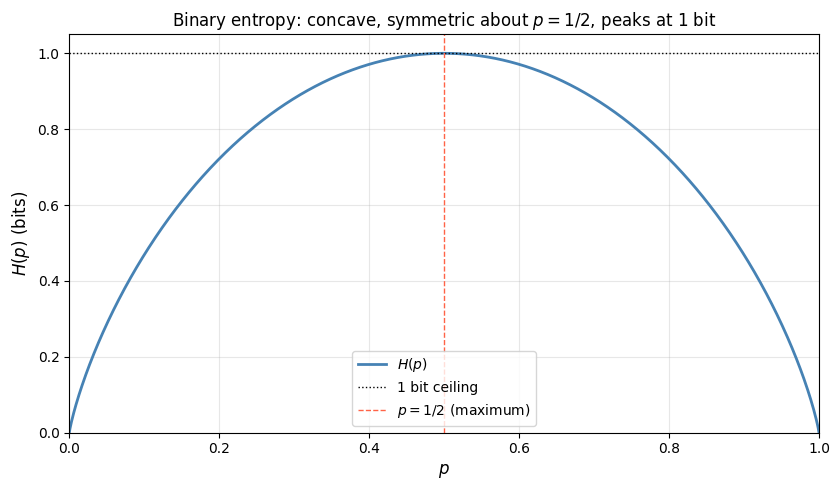

In [2]:
def H(p: np.ndarray) -> np.ndarray:
    """Binary entropy in bits. Handles the 0 log 0 = 0 boundary by clamping.

    Vectorized over array inputs. Returns 0 at p in {0, 1}.
    """
    p = np.asarray(p, dtype=float)
    out = np.zeros_like(p)
    mask = (p > 0.0) & (p < 1.0)
    pm = p[mask]
    out[mask] = -pm * np.log2(pm) - (1.0 - pm) * np.log2(1.0 - pm)
    return out


# Sanity check the spot values.
for q in [0.0, 0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]:
    print(f"  H({q:.2f}) = {H(np.array([q]))[0]:.6f} bits")

p_grid = np.linspace(0.0, 1.0, 1001)
Hp = H(p_grid)

fig, ax = plt.subplots(figsize=(8.5, 5.0))
ax.plot(p_grid, Hp, color="steelblue", linewidth=2, label=r"$H(p)$")
ax.axhline(1.0, color="black", linestyle=":", linewidth=1.0, label="1 bit ceiling")
ax.axvline(0.5, color="tomato", linestyle="--", linewidth=1.0, label=r"$p = 1/2$ (maximum)")
ax.set_xlabel(r"$p$", fontsize=12)
ax.set_ylabel(r"$H(p)$ (bits)", fontsize=12)
ax.set_title(r"Binary entropy: concave, symmetric about $p = 1/2$, peaks at $1$ bit", fontsize=12)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10, loc="lower center")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. BSC Capacity $C(\fprate) = 1 - H(\fprate)$

Chapter 8 §8.2 reviews the binary symmetric channel from chapter 2 §2.1 and quotes Shannon's capacity formula

$$C(\fprate) \;=\; 1 - H(\fprate), \qquad \fprate \in [0, 1/2].$$

At $\fprate = 0$ the channel is noiseless and $C = 1$ bit per channel use. At $\fprate = 1/2$ the input and output are independent (the channel is a fair coin) and $C = 0$: no information can be transmitted. For intermediate $\fprate$, the achievable rate is bounded by $1 - H(\fprate)$ and the gap $H(\fprate)$ is the cost the noise imposes on the channel. The same $H(\fprate)$ reappears as the floor for FNR-zero approximate sets in §8.3: the connection is the duality between channel coding (transmit one of $2^{nC}$ messages reliably) and source coding (describe one of $2^{-nH}$ objects compactly).

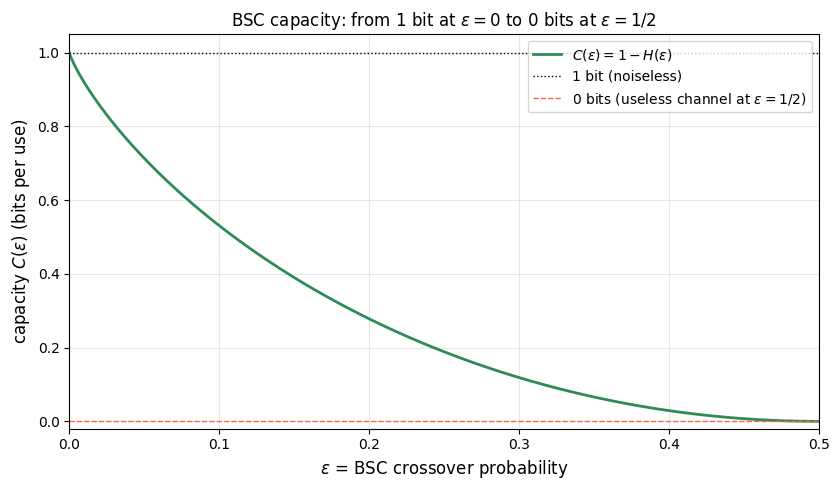


Spot values:
  epsilon = 0.00:  H = 0.0000,  C = 1.0000
  epsilon = 0.01:  H = 0.0808,  C = 0.9192
  epsilon = 0.05:  H = 0.2864,  C = 0.7136
  epsilon = 0.11:  H = 0.4999,  C = 0.5001
  epsilon = 0.25:  H = 0.8113,  C = 0.1887
  epsilon = 0.50:  H = 1.0000,  C = 0.0000


In [3]:
eps_grid = np.linspace(0.0, 0.5, 501)
C = 1.0 - H(eps_grid)

fig, ax = plt.subplots(figsize=(8.5, 5.0))
ax.plot(eps_grid, C, color="seagreen", linewidth=2, label=r"$C(\epsilon) = 1 - H(\epsilon)$")
ax.axhline(1.0, color="black", linestyle=":", linewidth=1.0, label="1 bit (noiseless)")
ax.axhline(0.0, color="tomato", linestyle="--", linewidth=1.0, label=r"$0$ bits (useless channel at $\epsilon = 1/2$)")
ax.set_xlabel(r"$\epsilon$ = BSC crossover probability", fontsize=12)
ax.set_ylabel(r"capacity $C(\epsilon)$ (bits per use)", fontsize=12)
ax.set_title(r"BSC capacity: from 1 bit at $\epsilon=0$ to 0 bits at $\epsilon=1/2$", fontsize=12)
ax.set_xlim(0, 0.5)
ax.set_ylim(-0.02, 1.05)
ax.legend(fontsize=10, loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Spot values:")
for q in [0.0, 0.01, 0.05, 0.11, 0.25, 0.5]:
    Hq = H(np.array([q]))[0]
    Cq = 1.0 - Hq
    print(f"  epsilon = {q:.2f}:  H = {Hq:.4f},  C = {Cq:.4f}")

## 3. Entropy Floor vs Standard Bloom Cost

Chapter 8 §8.3 (Theorem 8.1, entropy floor) states: any FNR-zero approximate set storing $n$ elements with false-positive rate $\fprate$ requires at least

$$\text{floor}(\fprate) \;=\; -\log_2 \fprate \quad \text{bits per element}$$

in expectation. The argument is a counting bound: the set must distinguish itself from the universe of all $n$-subsets of the ground set, and the false-positive budget controls how many extra elements the data structure can confuse with members.

Chapter 8 §8.4 derives the standard Bloom filter's space cost from its bit-array length $m$ and its hash count $k$. Optimizing $k$ for given $m, n$, the optimal false-positive rate is $\fprate^* = (1/2)^{m \ln 2 / n}$, which inverts to

$$\text{bloom}(\fprate) \;=\; \frac{m}{n} \;=\; \log_2(1/\fprate) \cdot \log_2 e \quad \text{bits per element}.$$

The two are proportional. The proportionality constant $\log_2 e \approx 1.4427$ is the structural overhead of the standard Bloom filter.

Spot checks (plan Task 9 numerical targets):
  epsilon =   1e-02: floor = 6.6439 bits, bloom = 9.5851 bits, ratio = 1.4427
  epsilon =   1e-03: floor = 9.9658 bits, bloom = 14.3776 bits, ratio = 1.4427
  epsilon =   1e-05: floor = 16.6096 bits, bloom = 23.9626 bits, ratio = 1.4427
  epsilon =   1e-01: floor = 3.3219 bits, bloom = 4.7925 bits, ratio = 1.4427


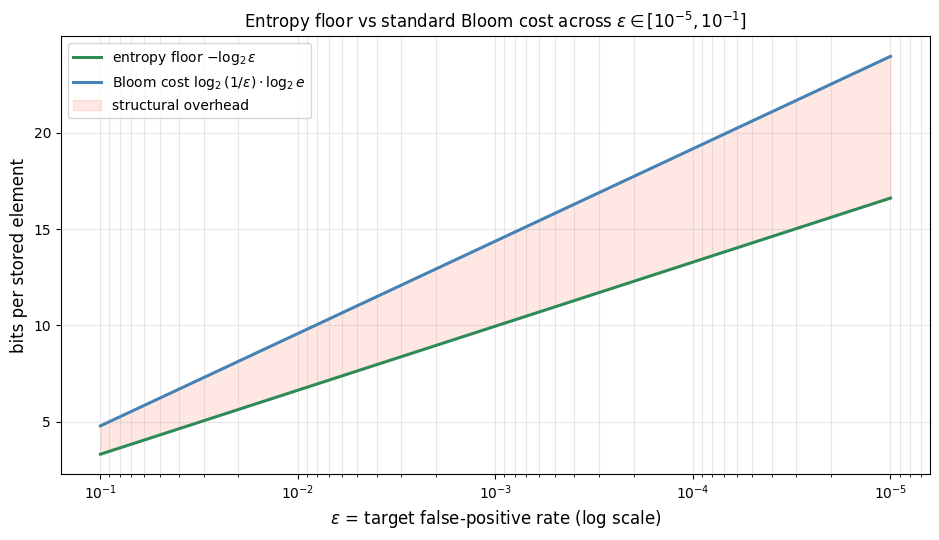

In [4]:
# Log-spaced fpr range: from 10^-5 (very tight filter) to 10^-1 (loose filter).
eps_log = np.logspace(-5, -1, 50)

floor_bits = -np.log2(eps_log)
bloom_bits = np.log2(1.0 / eps_log) * LOG2_E

# Numerical sanity checks against the plan targets.
def report(eps_val):
    f = -np.log2(eps_val)
    b = np.log2(1.0 / eps_val) * LOG2_E
    r = b / f
    print(f"  epsilon = {eps_val:>7.0e}: floor = {f:.4f} bits, bloom = {b:.4f} bits, ratio = {r:.4f}")

print("Spot checks (plan Task 9 numerical targets):")
report(0.01)    # expect floor=6.6439, bloom=9.5851, ratio=1.4427
report(0.001)   # expect floor=9.9658, bloom=14.3776, ratio=1.4427
report(1e-5)
report(0.1)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(eps_log, floor_bits, color="seagreen", linewidth=2.2,
        label=r"entropy floor $-\log_2 \epsilon$")
ax.plot(eps_log, bloom_bits, color="steelblue", linewidth=2.2,
        label=r"Bloom cost $\log_2(1/\epsilon) \cdot \log_2 e$")
ax.fill_between(eps_log, floor_bits, bloom_bits, color="tomato", alpha=0.15,
                label="structural overhead")
ax.set_xscale("log")
ax.invert_xaxis()  # tighter filters on the right
ax.set_xlabel(r"$\epsilon$ = target false-positive rate (log scale)", fontsize=12)
ax.set_ylabel("bits per stored element", fontsize=12)
ax.set_title(r"Entropy floor vs standard Bloom cost across $\epsilon \in [10^{-5}, 10^{-1}]$", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. The Constant 1.44 Ratio

Divide the Bloom cost by the entropy floor pointwise: the $\log_2(1/\fprate)$ factor cancels, leaving the bare constant $\log_2 e \approx 1.4427$. This is the verbal claim chapter 8 §8.4 quotes ("the standard Bloom filter is a constant $44\%$ above the floor"); the plot below shows it as a flat horizontal line across four decades of $\fprate$. If the ratio were a function of $\fprate$, the constant would have a name. It is not: the overhead is purely structural, baked into the bitmap-with-hashing construction, and independent of how tight the filter is set.

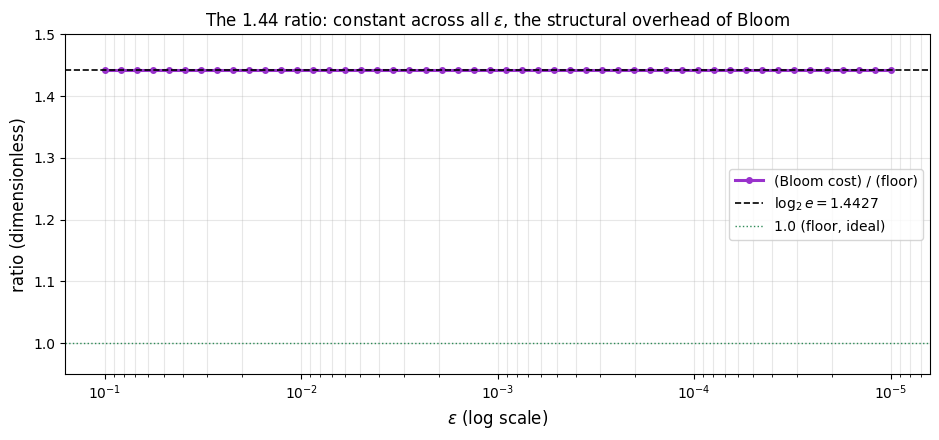


Ratio min over the sweep: 1.4426950409
Ratio max over the sweep: 1.4426950409
Ratio mean:               1.4426950409
log_2(e):                 1.4426950409
Max deviation from log_2(e): 2.22e-16


In [5]:
ratio = bloom_bits / floor_bits

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(eps_log, ratio, color="darkorchid", linewidth=2.2, marker="o", markersize=4,
        label="(Bloom cost) / (floor)")
ax.axhline(LOG2_E, color="black", linestyle="--", linewidth=1.2,
           label=fr"$\log_2 e = {LOG2_E:.4f}$")
ax.axhline(1.0, color="seagreen", linestyle=":", linewidth=1.0,
           label="1.0 (floor, ideal)")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlabel(r"$\epsilon$ (log scale)", fontsize=12)
ax.set_ylabel("ratio (dimensionless)", fontsize=12)
ax.set_title(r"The 1.44 ratio: constant across all $\epsilon$, the structural overhead of Bloom", fontsize=12)
ax.set_ylim(0.95, 1.50)
ax.legend(fontsize=10, loc="center right")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print()
print(f"Ratio min over the sweep: {ratio.min():.10f}")
print(f"Ratio max over the sweep: {ratio.max():.10f}")
print(f"Ratio mean:               {ratio.mean():.10f}")
print(f"log_2(e):                 {LOG2_E:.10f}")
print(f"Max deviation from log_2(e): {np.abs(ratio - LOG2_E).max():.2e}")

## 5. Absolute Overhead in Bits

The ratio plot shows the gap is multiplicatively constant. Subtracting instead of dividing tells the operational story: how many wasted bits per element does the Bloom filter pay relative to a hypothetical achievable filter at the floor? The answer is

$$\text{bloom}(\fprate) - \text{floor}(\fprate) \;=\; (\log_2 e - 1) \cdot (-\log_2 \fprate) \;\approx\; 0.4427 \cdot (-\log_2 \fprate).$$

It grows linearly in $-\log_2 \fprate$. At $\fprate = 0.01$ the gap is $\sim 2.94$ bits per element; at $\fprate = 10^{-5}$ it is $\sim 7.35$ bits. For a filter holding $n = 10^9$ elements at $\fprate = 10^{-5}$, the structural overhead is $7.35 \times 10^9$ bits, roughly $920\,\mathrm{MB}$ of pure waste relative to the entropy floor. That is the gap chapter 14's BHF closes.

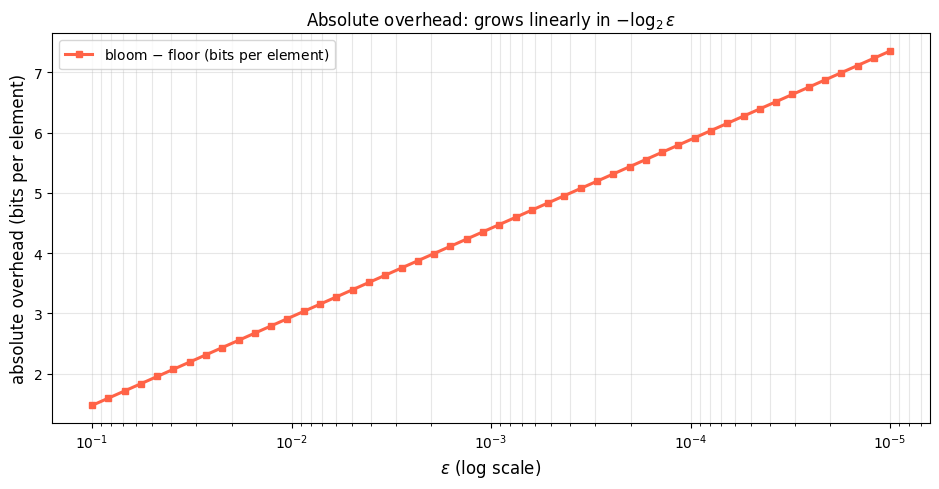


Operational cost of the structural overhead:
  epsilon =   1e-01: gap = 1.4706 bits/elem,  for n=10^9: ~184 MB wasted
  epsilon =   1e-02: gap = 2.9412 bits/elem,  for n=10^9: ~368 MB wasted
  epsilon =   1e-03: gap = 4.4118 bits/elem,  for n=10^9: ~551 MB wasted
  epsilon =   1e-04: gap = 5.8824 bits/elem,  for n=10^9: ~735 MB wasted
  epsilon =   1e-05: gap = 7.3530 bits/elem,  for n=10^9: ~919 MB wasted


In [6]:
overhead = bloom_bits - floor_bits

fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.plot(eps_log, overhead, color="tomato", linewidth=2.2, marker="s", markersize=4,
        label="bloom $-$ floor (bits per element)")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlabel(r"$\epsilon$ (log scale)", fontsize=12)
ax.set_ylabel("absolute overhead (bits per element)", fontsize=12)
ax.set_title(r"Absolute overhead: grows linearly in $-\log_2 \epsilon$", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("Operational cost of the structural overhead:")
for eps_val in [0.1, 0.01, 0.001, 1e-4, 1e-5]:
    gap = (LOG2_E - 1.0) * (-np.log2(eps_val))
    # For a filter of n = 10^9 elements:
    bytes_wasted = gap * 1e9 / 8.0
    print(f"  epsilon = {eps_val:>7.0e}: gap = {gap:.4f} bits/elem,  for n=10^9: ~{bytes_wasted / 1e6:.0f} MB wasted")

## 5b. The Library: `bernoulli.sets.entropy_bound`

Everything plotted above is the executable content of `bernoulli.sets.entropy_bound`. Given a target $\fprate$ it returns the floor $-\log_2 \fprate$, the Bloom cost $\log_2 e \cdot (-\log_2 \fprate)$, and the efficiency floor/actual. It also computes the **BHF** cost that sections 6 and 7 describe only in prose: $\lceil -\log_2 \fprate \rceil$ bits, the integer fingerprint width that closes the $1.44$ gap. We tabulate all three across the chapter's $\fprate$ values and confirm the floor and Bloom numbers match the curves plotted above.

In [7]:
from bernoulli.sets import entropy_bound as eb

print(f"{'fpr':>8s}  {'floor':>7s}  {'bloom':>7s}  {'bhf':>5s}  "
      f"{'bloom eff':>9s}  {'bhf eff':>8s}")
print("-" * 52)
for fpr in [0.1, 0.01, 0.001, 1e-4, 1e-5]:
    c = eb.compare(fpr)
    print(f"{fpr:>8.0e}  {c.floor_bits_per_key:>7.4f}  {c.bloom_bits_per_key:>7.4f}  "
          f"{c.bhf_bits_per_key:>5.1f}  {c.bloom_efficiency:>9.4f}  {c.bhf_efficiency:>8.4f}")

# The library's floor and Bloom curves match this notebook's arrays exactly.
floor_lib = np.array([eb.entropy_floor_bits_per_key(e) for e in eps_log])
bloom_lib = np.array([eb.bloom_bits_per_key(e) for e in eps_log])
print()
print(f"max |library floor - notebook floor| = {np.abs(floor_lib - floor_bits).max():.2e}")
print(f"max |library bloom - notebook bloom| = {np.abs(bloom_lib - bloom_bits).max():.2e}")
print()
print("Bloom efficiency is a flat ln(2) = 0.6931 at every fpr (the structural 1.44x).")
print("BHF efficiency stays near 1.0, dipping only by the integer-rounding slack of the")
print("fingerprint width: the gap chapter 14 closes, here as a single function call.")

     fpr    floor    bloom    bhf  bloom eff   bhf eff
----------------------------------------------------
   1e-01   3.3219   4.7925    4.0     0.6931    0.8305
   1e-02   6.6439   9.5851    7.0     0.6931    0.9491
   1e-03   9.9658  14.3776   10.0     0.6931    0.9966
   1e-04  13.2877  19.1701   14.0     0.6931    0.9491
   1e-05  16.6096  23.9626   17.0     0.6931    0.9770

max |library floor - notebook floor| = 0.00e+00
max |library bloom - notebook bloom| = 3.55e-15

Bloom efficiency is a flat ln(2) = 0.6931 at every fpr (the structural 1.44x).
BHF efficiency stays near 1.0, dipping only by the integer-rounding slack of the
fingerprint width: the gap chapter 14 closes, here as a single function call.


## 6. Reading the Gap: Where Chapters 14 and 15 Land

The $44\%$ multiplicative gap, equivalently the $0.4427 \cdot (-\log_2 \fprate)$ absolute gap, is not a quirk of one implementation or a Monte Carlo artefact. It is structural to the standard Bloom filter's representation: a bit array plus $k$ independent hash functions, set bits at insertion, all-bits-set test at query. Every variant in the Bloom family that keeps this skeleton inherits the same $\log_2 e$ overhead, up to lower-order terms.

There are two ways out of the gap, and Part III picks both up.

**Chapter 14: the Bernoulli hash filter (BHF).** A different construction whose acceptance predicate is a salted perfect hash rather than a bit array. The BHF achieves bits per element

$$\text{bhf}(\fprate) \;=\; -\log_2 \fprate + \mu(n),$$

where $\mu(n) \to 0$ as $n$ grows. It saturates the entropy floor up to a vanishing overhead. Chapter 14's contribution is exactly this: the constructive demonstration that the chapter 8 lower bound is achievable, not just a counting argument.

**Chapter 15: the Bernoulli perfect hash filter (BPHF).** A different axis entirely. The BPHF sets $\fprate = 0$ by construction: a query for any member of the stored set returns true, a query for any nonmember returns false, every time. The space cost on the FPR-zero axis is governed by a separate bound (the minimal perfect hash function lower bound, $\sim n \log_2 e$ bits for an $n$-element set), not the floor of §8.3. Chapter 15 makes this trade explicit: pay more space to remove false positives entirely. Many applications (cryptographic indexes, deduplication, encrypted search) want this axis, not the $\fprate > 0$ axis where Bloom and BHF live.

**The Bloom filter's place after chapters 14-15.** Bloom is not deprecated. It is cheap to build, cache-friendly, mature, and well understood. For workloads where $44\%$ of $-\log_2 \fprate$ bits per element is operationally negligible (small $n$, moderate $\fprate$, no memory pressure), the simplicity wins. Chapter 8's job is to mark the bit-budget question with a number, so that workloads where the $44\%$ matters can be identified and routed to the BHF (chapter 14) or BPHF (chapter 15) on principled grounds rather than habit.

## 7. Open Question: Can the Gap Be Closed Without Abandoning the Bitmap?

The standard Bloom filter's $\log_2 e$ overhead lives in the bitmap-with-hashing skeleton. A natural question: can the gap be closed without replacing that skeleton entirely?

**Partial answer: compressed Bloom filters.** Mitzenmacher (2002) observed that the bit array of an optimally tuned Bloom filter has bit-density $1/2$, so the array has entropy $1$ bit per array-bit, which is also its raw size in bits. But when the filter is tuned at a fixed transmission budget (rather than fixed in-memory size), one can over-allocate the array, drop the bit-density below $1/2$, then compress the array with arithmetic coding before shipping it. The compressed size approaches the entropy floor as the over-allocation factor grows. This recovers most of the $\log_2 e$ overhead at the cost of decompression on read, which is operationally fine for transmission-bound deployments and infeasible for in-memory query-bound ones.

**Full answer: replace the bitmap.** No compression scheme on a bitmap with hashing can do better than the chapter 8 entropy floor in expectation. To close the gap in the in-memory representation (not the compressed-on-disk representation), the data structure must abandon the bit array. The BHF (chapter 14) does this: its representation is a perfect hash function's bucket table plus a per-bucket fingerprint of $\lceil -\log_2 \fprate \rceil$ bits, with no wasted bit-array sparsity. The space cost is then $-\log_2 \fprate$ bits per element up to integer rounding and the perfect-hash overhead $\mu(n)$, both vanishing relative to the dominant $-\log_2 \fprate$ term.

**The structural lesson.** Algorithmic constants that survive across an entire family of designs (here, $\log_2 e$ for any bitmap-with-hashing) signal a structural feature of the design family, not an implementation detail to be optimized away. Closing such a gap requires stepping outside the family, which is the move chapter 14 makes. Plotting the ratio against $\fprate$ on a log scale (§4 above) is the diagnostic that exposes the constant: a flat line across decades is the visual signature of a structural overhead.

---

## Closing: Cross-References and Next Steps

**Chapter 8** establishes the bit-budget question: the entropy floor $-\log_2 \fprate$ bits per element (§8.3) is the unavoidable cost for an FNR-zero filter at FPR $\fprate$, and the standard Bloom filter sits at $\log_2 e \approx 1.4427$ times the floor (§8.4). The chapter 2 BSC capacity $C(\fprate) = 1 - H(\fprate)$ returns in §8.2 as the channel-coding side of the same coin.

**Chapter 5** (Approximate Sets) introduced the Bloom filter; chapter 8 says what its space cost is in absolute terms and how far above the achievable floor it lives.

**Chapter 14** (Optimal Bernoulli Sets / BHF) is the constructive payoff: the floor is achievable up to a vanishing overhead. Chapter 8's lower bound is not just a counting argument waiting for an existence proof; the BHF is the proof, and chapter 14 is where the construction lands.

**Chapter 15** (Bernoulli Perfect Hash Filter) covers the orthogonal $\fprate = 0$ axis, with its own space bound and its own deployment regime.

**Summary of what this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| §8.1 | $H(p)$ is concave, symmetric about $1/2$, peaks at $1$ bit | Yes |
| §8.2 | $C(\fprate) = 1 - H(\fprate)$ runs from $1$ at $\fprate=0$ to $0$ at $\fprate=1/2$ | Yes |
| §8.3 | At $\fprate = 0.01$, floor $= -\log_2(0.01) = 6.6439$ bits per element | Yes |
| §8.4 | At $\fprate = 0.01$, Bloom cost $= 9.5851$ bits per element | Yes |
| §8.4 | Ratio is constant at $\log_2 e \approx 1.4427$ across $\fprate \in [10^{-5}, 10^{-1}]$ | Yes |
| §8.4 | Absolute overhead $(\log_2 e - 1)(-\log_2 \fprate) \approx 0.4427 \cdot (-\log_2 \fprate)$ grows linearly as $\fprate$ shrinks | Yes |